# Electron Density and Electrostatic Potential Surfaces

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/temp/08-surfaces.ipynb)
:::


In [25]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import skimage          # scikit-image draws the static orbital and density surfaces
except ImportError:
    !pip -q install scikit-image
    import skimage

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    sys.path.insert(0, "..")                    # psi4_helpers.py is one folder up
    plt.style.use("../styles/tufte.mplstyle")
    nproc = 4          # house limit: 4 threads

import psi4_helpers as ph

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = False

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
_ = psi4.set_memory("2 GB")


A molecule has no sharp edge: its electron density fades away smoothly. A useful working definition of its "surface" is a **contour of constant electron density**. The contour at 0.001 electrons per bohr³ (0.001 au) encloses about 96–98 % of the electrons and matches the familiar van der Waals size of molecules well (Bader *et al.*, *J. Am. Chem. Soc.* **1987**, *109*, 7968). On that surface we can paint the **electrostatic potential** (ESP): the energy a small positive charge would feel there. This makes the polarity of water visible.

## What You Will Learn
- How to write the electron density and ESP to **cube files** with `psi4.cubeprop()`.
- How to draw a density **isosurface** and colour it by the ESP.
- How to read a cube file with *Python* to find the most negative and most positive regions of the surface.

In [26]:
psi4.set_output_file("output/08-surfaces.out", False);
cube_dir = output_dir / "cubes"
cube_dir.mkdir(exist_ok=True)

## 1. Calculate the Wavefunction and Write Cube Files

```{note} Psi4 settings in this cell
:class: dropdown
`b3lyp/aug-cc-pvdz`
: The density far from the nuclei is what defines the surface, so we use a basis set with **diffuse** functions (`aug-`). In the *Charges and Dipole* notebook this level reproduced the experimental dipole moment. *Alternatives:* `hf/6-31g*` gives a qualitatively identical picture and is the traditional choice for ESP maps; `b3lyp/6-31+g*` is a cheaper diffuse basis.

`cubeprop_tasks: ["density", "esp"]`
: What to write. `density` writes the alpha (`Da`), beta (`Db`), total (`Dt`) and spin (`Ds`) densities; `esp` writes the total density and the ESP (`ESP.cube`). Other tasks: `orbitals`, `frontier_orbitals`, `elf` (electron localization function), `lol`, `dual_descriptor`, `basis_functions`.

`cubeprop_filepath`
: The folder for the cube files. Cube files are large (here about 2.5 MB each), so we keep them in `output/cubes`.

`cubic_grid_spacing` (default 0.2 bohr) and `cubic_grid_overage` (default 4.0 bohr)
: The spacing of the grid points and how far the box extends beyond the outermost nuclei. We increase the overage to 5 bohr so the 0.001 au surface fits comfortably inside the box. A finer spacing (0.1 bohr) gives smoother pictures but files eight times larger.
```

In [27]:
water = psi4.geometry("""
0 1
O
H 1 0.9578
H 1 0.9578 2 104.48
""")

psi4.set_options({
    "basis": "aug-cc-pvdz",
    "scf_type": "df",
    "cubeprop_tasks": ["density", "elf"],
    "cubeprop_filepath": str(cube_dir),
    "cubic_grid_spacing": [0.2, 0.2, 0.2],
    "cubic_grid_overage": [5.0, 5.0, 5.0],
})

E, wfn = psi4.energy("b3lyp", molecule=water, return_wfn=True)
psi4.cubeprop(wfn)
print(sorted(p.name for p in cube_dir.iterdir()))

['Da.cube', 'Db.cube', 'Ds.cube', 'Dt.cube', 'ELFa.cube', 'ELFb.cube', 'ESP.cube', 'geom.xyz']


## 2. The Density Surface

We draw the total density `Dt.cube` at an isovalue of 0.001 au as a transparent surface around a ball-and-stick model.

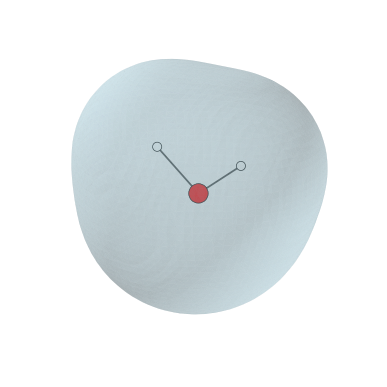

In [31]:
ph.show_density(cube_dir / "Dt.cube", isoval=0.001, mol=water, interactive=INTERACTIVE, transparency=0.7)

## 3. Mapping the Electrostatic Potential

Now we colour the same surface by the ESP. Red is negative (where a proton would be attracted: the oxygen lone pairs), blue is positive (where an anion or lone pair would be attracted: the hydrogens).

```{note} Settings for `ph.show_density()`
:class: dropdown
`isoval`
: The density contour drawn as the surface (0.001 au here).

`esp_cube_path`
: A second cube whose values colour the surface, here `ESP.cube`.

`esp_range`
: The colour scale runs red–white–blue from `-esp_range` to `+esp_range`. The range ±0.05 hartree/e (±130 kJ/mol per unit charge) suits neutral molecules; ions need a wider range.

`transparency`
: How see-through the surface is, from 0 (solid) to 1 (invisible). The plain density surface above uses 0.75 so the molecule shows through; the ESP map uses 0.4 so its colours stay strong.

`interactive`
: `False` draws a fixed picture; `True` draws a 3D surface you can rotate. Set `INTERACTIVE = True` in the first cell and rerun the notebook to get the rotatable version.
```

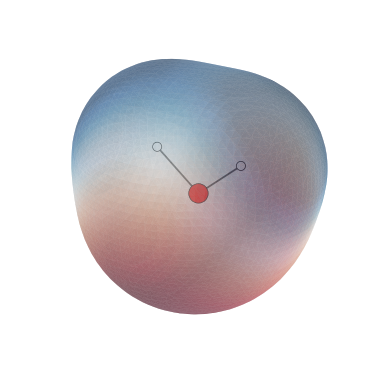

In [32]:
ph.show_density(cube_dir / "Dt.cube", isoval=0.001,
                esp_cube_path=cube_dir / "ESP.cube", esp_range=0.05,
                mol=water, interactive=INTERACTIVE, transparency=0.6)

## 4. Numbers from the Cube Files

A cube file is plain text: a header with the grid origin, spacing and atoms, then all the values. We read both cubes with *numpy*, pick out the grid points that lie close to the 0.001 au surface, and find the extreme ESP values there. We also estimate the **volume** enclosed by the surface by counting grid points.

In [30]:
def read_cube(path):
    """Return (values as a 3D array, grid step volume in bohr^3) from a Gaussian cube file."""
    lines = Path(path).read_text().splitlines()
    natoms = abs(int(lines[2].split()[0]))
    n, axes = [], []
    for line in lines[3:6]:
        parts = line.split()
        n.append(int(parts[0]))
        axes.append([float(v) for v in parts[1:4]])
    values = np.array(" ".join(lines[6 + natoms:]).split(), dtype=float).reshape(n)
    voxel = abs(np.linalg.det(np.array(axes)))
    return values, voxel

rho, voxel = read_cube(cube_dir / "Dt.cube")
esp, _ = read_cube(cube_dir / "ESP.cube")

on_surface = np.abs(rho - 0.001) < 0.0002          # points close to the 0.001 au contour
h2kJ = psi4.constants.hartree2kJmol
print(f"Most negative ESP on the surface: {esp[on_surface].min() * h2kJ:7.1f} kJ/mol")
print(f"Most positive ESP on the surface: {esp[on_surface].max() * h2kJ:7.1f} kJ/mol")

volume_bohr3 = (rho >= 0.001).sum() * voxel
print(f"Volume inside the 0.001 au surface: {volume_bohr3 * psi4.constants.bohr2angstroms**3:.1f} Å^3")

Most negative ESP on the surface:  -137.4 kJ/mol
Most positive ESP on the surface:   182.7 kJ/mol
Volume inside the 0.001 au surface: 28.7 Å^3


The most negative region sits over the oxygen lone pairs and the most positive region over the hydrogens. These two "hot spots" are where water will donate and accept **hydrogen bonds**, which we test in the *Hydrogen Bonding* notebook. ESP extremes like these correlate well with hydrogen-bond acidity and basicity across many molecules.

```{tip} Try it
- Change the isovalue to 0.002 au and watch the surface shrink.
- Compare the ESP map of water with methanol (`CO`) or ammonia (`N`) built with *RDKit* (see the *Structure* notebook).
- Try `"cubeprop_tasks": ["elf"]`. The **electron localization function** shows where electron pairs (bonds and lone pairs) are found.
```

## Summary
- `psi4.cubeprop()` writes the density, ESP, orbitals and other grids as cube files.
- The 0.001 au density contour is a practical molecular surface.
- Colouring it by the ESP shows where a molecule is electron-rich and electron-poor.